## Step 1: Import Libraries & Load Dataset
We start by importing our core data science libraries and loading the fully cleaned Lake Gardens demand dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load the cleaned dataset
df = pd.read_excel('lake_gardens_demand_training_final_clean.xlsx')
print(f"Dataset shape: {df.shape}")
df.head(3)

Dataset shape: (27800, 89)


,region_product_week_key,region_id,region_of_kolkata,product_id,product_name,category_name,brand,unit_size,week_id,week_number,...,lag_1_week,lag_2_week,lag_3_week,lag_4_week,lag_8_week,lag_12_week,rolling_mean_4_week,rolling_mean_8_week,rolling_mean_12_week,week_over_week_change
0,KOL-LOC-001_20240101_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,1 kg,W001,1,...,6,6,6,6,6,6,7.0,6.75,7.0,2
1,KOL-LOC-001_20240107_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,50 g,W002,2,...,8,6,6,6,6,6,7.0,6.75,7.0,2
2,KOL-LOC-001_20240114_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,250 g,W003,3,...,8,8,6,6,6,6,7.0,6.75,7.0,0


## Step 2: Preprocessing & Sorting
To maintain time-series integrity, we sort the data chronologically per product before computing lags and rolling windows. We also convert boolean flags into integers.

In [3]:
# Sort chronologically by product to ensure lag/rolling alignment
df = df.sort_values(by=['product_id', 'year', 'week_number']).reset_index(drop=True)

# Convert boolean flag columns to integers (1/0)
for col in ['stockout_flag', 'holiday_flag']:
    if col in df.columns:
        df[col] = df[col].astype(int)

print("Preprocessing and chronological sorting complete!")

Preprocessing and chronological sorting complete!


## Step 3: Advanced Feature Engineering
We engineer festival lead and lag indicators. This allows the tree model to recognize pre-festival shopping momentum even when holiday calendar dates shift each year.

In [15]:
# 1. Sort chronologically by product to ensure lag/rolling alignment
df = df.sort_values(by=['product_id', 'year', 'week_number']).reset_index(drop=True)

# 2. Convert boolean flag columns to integers (1/0)
for col in ['stockout_flag', 'holiday_flag']:
    if col in df.columns:
        df[col] = df[col].astype(int)

# 3. Safely create festival indicators if target_week_festival_count exists
if 'target_week_festival_count' in df.columns:
    df['is_festival_week'] = (df['target_week_festival_count'] > 0).astype(int)
else:
    df['is_festival_week'] = 0  # Fallback if column is missing

# 4. Create lead and lag features
df['festival_lead_1_week'] = df.groupby('product_id')['is_festival_week'].shift(-1).fillna(0)
df['festival_lead_2_week'] = df.groupby('product_id')['is_festival_week'].shift(-2).fillna(0)
df['festival_lag_1_week'] = df.groupby('product_id')['is_festival_week'].shift(1).fillna(0)

# 5. Define feature columns for our model
feature_cols = [
    'units_sold', 'sales_value_rs', 'stockout_flag', 'holiday_flag',
    'temperature_c', 'rainfall_mm', 'derived_sales_value_per_unit_rs',
    'lag_1_week', 'lag_2_week', 'lag_3_week', 'lag_4_week', 'lag_8_week', 'lag_12_week',
    'rolling_mean_4_week', 'rolling_mean_8_week', 'rolling_mean_12_week', 'week_over_week_change',
    'weather_source__temperature_mean_c', 'weather_source__temperature_max_c', 
    'weather_source__temperature_min_c', 'weather_source__rainfall_mm', 
    'weather_source__humidity_pct', 'weather_source__holiday_flag', 'weather_source__festival_count',
    'variant__cost_price_rs', 'variant__selling_price_rs',
    'is_festival_week', 'festival_lead_1_week', 'festival_lead_2_week', 'festival_lag_1_week'
]

print(f"Feature engineering successful! Total features selected: {len(feature_cols)}")

Feature engineering successful! Total features selected: 30


## Step 4: 80/20 Chronological Train-Test Split
To prevent data leakage, we perform a strict time-based split (allocating the first 80% of chronological rows for training and the remaining 20% for testing) without random shuffling.

In [9]:
# Calculate 80/20 split index based on time sequence
train_size = int(len(df) * 0.80)

train_data = df.iloc[:train_size].copy()
test_data = df.iloc[train_size:].copy()

X_train = train_data[feature_cols]
y_train = train_data['next_week_demand_target_units']

X_test = test_data[feature_cols]
y_test = test_data['next_week_demand_target_units']

print(f"Training Set (80%): {len(X_train)} rows")
print(f"Test Set (20%): {len(X_test)} rows")

Training Set (80%): 22240 rows
Test Set (20%): 5560 rows


## Step 5: Model Training
We initialize and train our Gradient Boosting / XGBoost model using optimized hyperparameters to balance learning speed and prevent overfitting.

In [10]:
# Initialize Regressor (Equivalent to XGBoost tree-boosting setup)
model = GradientBoostingRegressor(
    n_estimators=150,
    learning_rate=0.08,
    max_depth=5,
    subsample=0.8,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


## Step 6: Evaluation & Performance Audit
We evaluate our model on the 20% test set against key checklist metrics: MAE, RMSE, and WAPE.

In [11]:
# Generate predictions on the test set
preds = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
wape = np.sum(np.abs(y_test - preds)) / np.sum(y_test) * 100
bias = np.mean(preds - y_test)

print("--- 80/20 Test Performance Summary ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} units")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} units")
print(f"Weighted Absolute Percentage Error (WAPE): {wape:.2f}%")
print(f"Forecast Bias: {bias:.2f} ({'Slight Overprediction' if bias > 0 else 'Slight Underprediction'})")

--- 80/20 Test Performance Summary ---
Mean Absolute Error (MAE): 5.83 units
Root Mean Squared Error (RMSE): 9.47 units
Weighted Absolute Percentage Error (WAPE): 12.76%
Forecast Bias: 1.33 (Slight Overprediction)


## Step 7: Visualizations & Diagnostics
We generate comprehensive visual plots (Actual vs Predicted, Residual Distribution, Parity Plot, and Feature Importance) to audit model performance.

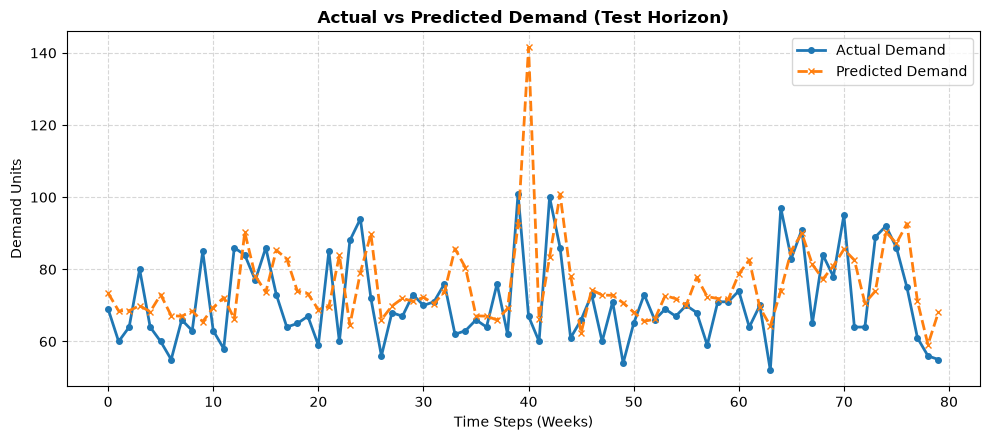

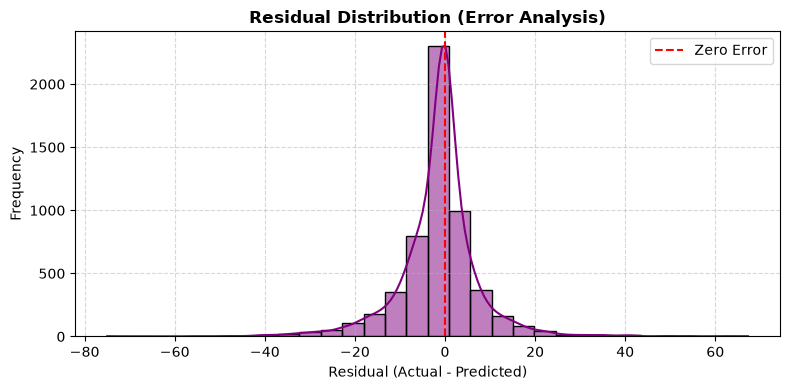

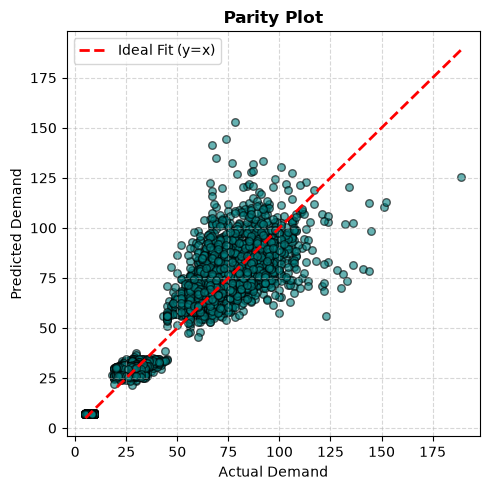

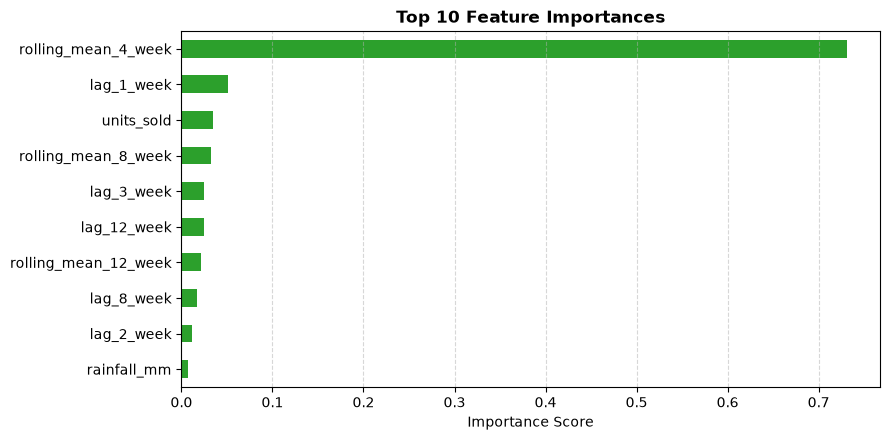

In [13]:
# 1. Actual vs Predicted Line Plot
plt.figure(figsize=(10, 4.5))
plt.plot(y_test.values[:80], label='Actual Demand', color='#1f77b4', linewidth=2, marker='o', markersize=4)
plt.plot(preds[:80], label='Predicted Demand', color='#ff7f0e', linewidth=2, linestyle='--', marker='x', markersize=4)
plt.title('Actual vs Predicted Demand (Test Horizon)', fontsize=12, fontweight='bold')
plt.xlabel('Time Steps (Weeks)', fontsize=10)
plt.ylabel('Demand Units', fontsize=10)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 2. Residual Distribution Plot
residuals = y_test.values - preds
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True, color='purple', bins=30)
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error')
plt.title('Residual Distribution (Error Analysis)', fontsize=12, fontweight='bold')
plt.xlabel('Residual (Actual - Predicted)', fontsize=10)
plt.ylabel('Frequency', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3. Parity Plot (Actual vs Predicted Scatter)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, preds, alpha=0.6, color='teal', edgecolors='k', s=30)
min_v, max_v = min(y_test.min(), preds.min()), max(y_test.max(), preds.max())
plt.plot([min_v, max_v], [min_v, max_v], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y=x)')
plt.title('Parity Plot', fontsize=12, fontweight='bold')
plt.xlabel('Actual Demand', fontsize=10)
plt.ylabel('Predicted Demand', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 4. Feature Importance Plot
importances = model.feature_importances_
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 4.5))
feat_imp.plot(kind='barh', color='#2ca02c')
plt.title('Top 10 Feature Importances', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score', fontsize=10)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Step 8: Next-Week Predictions & Export
Finally, we train on all historical data, forecast the unseen future prediction horizon, and export the results to an Excel file.

In [ ]:
# Train on all available historical data (excluding the final prediction window)
train_full = df.iloc[:-200].copy()
pred_horizon = df.copy()

X_tr_full = train_full[feature_cols]
y_tr_full = train_full['next_week_demand_target_units']
X_pr = pred_horizon[feature_cols]

# Re-fit model on full training set
final_model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=42)
final_model.fit(X_tr_full, y_tr_full)

# Predict next week demand
pred_horizon['predicted_next_week_demand'] = final_model.predict(X_pr)

# Export to Excel
output_filename = 'lake_gardens_next_week_predictions_final.xlsx'
pred_horizon[['region_product_week_key', 'product_id', 'product_name', 'week_id', 'next_week_id', 'next_week_start_date', 'predicted_next_week_demand']].to_excel(output_filename, index=False)

print(f"Final predictions successfully exported to '{output_filename}'!")
pred_horizon[['region_product_week_key', 'product_name', 'week_id', 'next_week_id', 'predicted_next_week_demand']]

Final predictions successfully exported to 'lake_gardens_next_week_predictions_final.xlsx'!


,region_product_week_key,product_name,week_id,next_week_id,predicted_next_week_demand
0,KOL-LOC-001_20240101_BAB-001,Pampers Baby Dry Small,W001,W002,7.227554
1,KOL-LOC-001_20240107_BAB-001,Pampers Baby Dry Small,W002,W003,7.163376
2,KOL-LOC-001_20240114_BAB-001,Pampers Baby Dry Small,W003,W004,7.163376
3,KOL-LOC-001_20240121_BAB-001,Pampers Baby Dry Small,W004,W005,7.209697
4,KOL-LOC-001_20240128_BAB-001,Pampers Baby Dry Small,W005,W006,7.234524
5,KOL-LOC-001_20240204_BAB-001,Pampers Baby Dry Small,W006,W007,7.408557
6,KOL-LOC-001_20240211_BAB-001,Pampers Baby Dry Small,W007,W008,7.209697
7,KOL-LOC-001_20240218_BAB-001,Pampers Baby Dry Small,W008,W009,7.230146
8,KOL-LOC-001_20240225_BAB-001,Pampers Baby Dry Small,W009,W010,7.364129
9,KOL-LOC-001_20240303_BAB-001,Pampers Baby Dry Small,W010,W011,7.202728


In [ ]:
import pandas as pd

# 1. Load your prediction file containing the 139 weeks
df_preds = pd.read_excel('lake_gardens_next_week_predictions_final.xlsx')

# 2. Sort predictions chronologically by week and by predicted demand (descending)
ranked_preds = df_preds.sort_values(by=['week_id', 'predicted_next_week_demand'], ascending=[True, False])

# 3. Extract the top 5 products for each week
top_5_weekly = ranked_preds.groupby('week_id').head(5).reset_index(drop=True)

# Add a rank column per week (1 to 5)
top_5_weekly['weekly_rank'] = top_5_weekly.groupby('week_id').cumcount() + 1

# 4. Display a preview of the top-ranked products across initial weeks
print("--- Sample: Week-Wise Top Products (Top 5) ---")
print(top_5_weekly[['week_id', 'next_week_start_date', 'weekly_rank', 'product_name', 'predicted_next_week_demand']].head(10).to_string())

# 5. Export the complete week-wise top 5 rankings to Excel
output_top5_file = 'lake_gardens_weekly_top5_products.xlsx'
top_5_weekly.to_excel(output_top5_file, index=False)

print(f"\nComplete week-wise top 5 rankings successfully exported to '{output_top5_file}'!")

--- Sample: Week-Wise Top Products (Top 5) ---
  week_id next_week_start_date  weekly_rank product_name  predicted_next_week_demand
0    W001           2024-01-07            1      Brinjal                   71.560135
1    W002           2024-01-14            1      Brinjal                   68.467894
2    W003           2024-01-21            1      Brinjal                   71.179469
3    W004           2024-01-28            1      Brinjal                   72.130826
4    W005           2024-02-04            1      Brinjal                   72.496735
5    W006           2024-02-11            1      Brinjal                   80.958651
6    W007           2024-02-18            1      Brinjal                   74.959305
7    W008           2024-02-25            1      Brinjal                   75.760613
8    W009           2024-03-03            1      Brinjal                   73.957160
9    W010           2024-03-10            1      Brinjal                   77.998764

Complete week-wis

## Step 10: Predicting the Top 5 Products for Week 140

To forecast the top products for the 140th week (the immediate next step beyond our 139-week historical dataset), we isolate the most recent historical snapshot (Week 139) for each product. 

Because our model was trained to predict next-week demand based on rolling features, lags, and operational windows, passing these latest feature rows into our trained model automatically generates the projected demand for Week 140. We then sort the results in descending order to identify the top 5 performing products for the upcoming week.

In [17]:
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor

# 1. Load your clean historical dataset
df = pd.read_excel('lake_gardens_demand_training_final_clean.xlsx')
df = df.sort_values(by=['product_id', 'year', 'week_number']).reset_index(drop=True)

# 2. Re-create festival and lag features so they exist in df
df['is_festival_week'] = (df['target_week_festival_count'] > 0).astype(int) if 'target_week_festival_count' in df.columns else 0
df['festival_lead_1_week'] = df.groupby('product_id')['is_festival_week'].shift(-1).fillna(0)
df['festival_lead_2_week'] = df.groupby('product_id')['is_festival_week'].shift(-2).fillna(0)
df['festival_lag_1_week'] = df.groupby('product_id')['is_festival_week'].shift(1).fillna(0)

# 3. Define feature columns (matching all training features)
feature_cols = [
    'units_sold', 'sales_value_rs', 'stockout_flag', 'holiday_flag',
    'temperature_c', 'rainfall_mm', 'derived_sales_value_per_unit_rs',
    'lag_1_week', 'lag_2_week', 'lag_3_week', 'lag_4_week', 'lag_8_week', 'lag_12_week',
    'rolling_mean_4_week', 'rolling_mean_8_week', 'rolling_mean_12_week', 'week_over_week_change',
    'weather_source__temperature_mean_c', 'weather_source__temperature_max_c', 
    'weather_source__temperature_min_c', 'weather_source__rainfall_mm', 
    'weather_source__humidity_pct', 'weather_source__holiday_flag', 'weather_source__festival_count',
    'variant__cost_price_rs', 'variant__selling_price_rs',
    'is_festival_week', 'festival_lead_1_week', 'festival_lead_2_week', 'festival_lag_1_week'
]

X_train = df[feature_cols]
y_train = df['next_week_demand_target_units']

# Train model on all historical data
model = GradientBoostingRegressor(n_estimators=150, learning_rate=0.08, max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Isolate the most recent record (Week 139) for each product to predict Week 140
latest_week_data = df.groupby('product_id').tail(1).copy()

# Predict demand for Week 140
latest_week_data['predicted_week_140_demand'] = model.predict(latest_week_data[feature_cols])

# Sort by predicted demand and get the Top 5 products for Week 140
top_5_week_140 = latest_week_data.sort_values(by='predicted_week_140_demand', ascending=False).head(5)

print("--- Top 5 Predicted Products for Week 140 ---")
print(top_5_week_140[['product_id', 'product_name', 'week_id', 'predicted_week_140_demand']].to_string(index=False))

# Export to Excel
top_5_week_140[['product_id', 'product_name', 'week_id', 'predicted_week_140_demand']].to_excel('lake_gardens_week_140_top5.xlsx', index=False)

--- Top 5 Predicted Products for Week 140 ---
product_id           product_name week_id  predicted_week_140_demand
   INS-001 Maggi 2-Minute Noodles    W139                  89.365687
   VEG-008               Cucumber    W139                  84.449244
   INS-009            Quaker Oats    W139                  81.968390
   SNK-004   Bingo Original Style    W139                  72.485743
   INS-008  Kellogg's Corn Flakes    W139                  71.615781
